In [11]:
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [ ]:
class Signal:
    """
    Classe Signal qui permet de charger et de visualiser les données météorologiques de Strasbourg Entzheim.
    """

    def __init__(self) -> None:

        self.__file_path = (
            Path.cwd() / ".." / "data" / "strasbourg_entzheim.csv"
        ).resolve()

        self.__df = pd.read_csv(filepath_or_buffer=self.__file_path, sep=",")

        # température moyenne
        self.tavg = self.__df["tavg"].to_numpy()

        # température minimum
        self.tmin = self.__df["tmin"].to_numpy()

        # température maximum
        self.tmax = self.__df["tmax"].to_numpy()

        # taux de précipitation
        self.prcp = self.__df["prcp"].to_numpy()

        # taux de neige
        self.snow = self.__df["snow"].to_numpy()

        # direction du vent
        self.wdir = self.__df["wdir"].to_numpy()

        # vitesse du vent (en km/h)
        self.wspd = self.__df["wspd"].to_numpy()

        # pic de rafale (en km/h)
        self.wpgt = self.__df["wpgt"].to_numpy()

        # pression atmosphérique (en hPa)
        self.pres = self.__df["pres"].to_numpy()

        # durée d’ensoleillement (en minutes)
        self.tsun = self.__df["tsun"].to_numpy()

        self.__data = {
            "tavg": (self.tavg, "°C"),
            "tmin": (self.tmin, "°C"),
            "tmax": (self.tmax, "°C"),
            "prcp": (self.prcp, "mm"),
            "snow": (self.snow, "mm"),
            "wdir": (self.wdir, "°"),
            "wspd": (self.wspd, "km/h"),
            "wpgt": (self.wpgt, "km/h"),
            "pres": (self.pres, "hPa"),
            "tsun": (self.tsun, "min"),
        }

    def __plot(
        self,
        data: tuple[np.ndarray, str] | list[tuple[np.ndarray, str]],
        lab_x: str,
        lab_y: str,
        title: str,
        x_values: np.ndarray | None = None,
        styles: list[dict[str, Any]] | None = None,
        stem: bool = False,
        show_legend: bool = True,
    ) -> None:
        """
        Permet d'afficher le plot d'un ou plusieurs signal

        Args:
            data (tuple[np.ndarray, str] | list[tuple[np.ndarray, str]]): données à afficher, chaque tuple contient un tableau de valeurs et un label.
            lab_x (str): label de l'axe des abscisses.
            lab_y (str): label de l'axe des ordonnées.
            title (str): titre du plot.
            x_values (np.ndarray | None, optional): valeurs de l'axe des abscisses. Defaults to None.
            styles (list[dict[str, Any]] | None, optional): styles pour chaque série. Defaults to None.
            stem (bool, optional): si True, affiche un plot en tiges. Defaults to False.
            show_legend (bool, optional): affiche la légende. Defaults to True.
        """
        plt.figure(figsize=(10, 5))

        series = [data] if isinstance(data, tuple) else data
        for i, (values, label) in enumerate(series):
            style = styles[i] if styles is not None else {}
            if stem:
                x = x_values if x_values is not None else np.arange(len(values))
                plt.stem(x, values, markerfmt=" ", basefmt=" ", label=label)
            elif x_values is None:
                plt.plot(values, label=label, **style)
            else:
                plt.plot(x_values, values, label=label, **style)

        plt.title(title)
        plt.xlabel(lab_x)
        plt.ylabel(lab_y)
        plt.grid()

        if show_legend:
            plt.legend()

        plt.show()

    def __check_data(self, donnée: str | tuple[str]) -> None:
        """
        Vérifie si la donnée est valide

        Args:
            donnée (str | tuple): Nom de la donnée à vérifier.

        Raises:
            ValueError: Si la donnée n'est pas valide.
        """

        if isinstance(donnée, tuple):
            for d in donnée:
                if d not in self.__data:
                    raise ValueError(f"{d} n'est pas une donnée valide.")
        else:
            if donnée not in self.__data:
                raise ValueError(f"{donnée} n'est pas une donnée valide.")

    def plot_signal(
        self,
        donnée: str | np.ndarray | tuple[str | np.ndarray],
        start: int = 0,
        end: int = 365,
    ) -> None:
        """
        Génère le plot d'un ou plusieurs signal

        Args:
            donnée (str | tuple): Nom de la donnée ou tuple de noms de données à afficher.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.

        Raises:
            ValueError: Si la donnée n'est pas valide.
        """
        if isinstance(donnée, tuple):
            données = donnée
        else:
            données = (donnée,)

        series = []
        labels = []
        for d in données:
            if isinstance(d, np.ndarray):
                valeurs = d
                unité = "unité inconnue"
                label = "Signal inconnu"
            else:
                self.__check_data(d)
                valeurs, unité = self.__data[d]
                label = f"Signal de {d} ({unité})"

            x = np.asarray(valeurs[start:end], dtype=float)

            moyenne = np.nanmean(x)
            ecart_type = np.nanstd(x)

            print(f"moyenne : {moyenne} / écart type : {ecart_type}")

            series.append((x, f"{d} ({unité})"))
            labels.append(label)

        self.__plot(series, "Temps (jours)", "Valeur", f"Signal de {', '.join(labels)}")

    def signal_data(
        self, donnée: str | np.ndarray, start: int = 0, end: int = 365
    ) -> tuple[np.ndarray, np.ndarray, str, np.ndarray, float, np.ndarray, int]:
        """
        Retourne les données d'un signal

        Args:
            donnée (str | np.ndarray): Nom de la donnée à afficher ou tableau de données.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.

        Raises:
            ValueError: Si la donnée n'est pas valide.

        Returns:
            tuple[np.ndarray, np.ndarray, str, np.ndarray, float, np.ndarray, int]: Amplitude, fréquence, unité, phase, valeur moyenne, signal et longueur du signal.
        """
        if isinstance(donnée, np.ndarray):
            valeurs = donnée
            unite = "unité inconnue"
        else:
            self.__check_data(donnée)
            valeurs, unite = self.__data[donnée]

        x = np.asarray(valeurs[start:end], dtype=float)

        len_x = len(x)

        if np.isnan(
            x
        ).all():  # Check si les données contiennent que des valeurs manquantes
            raise ValueError(f"Les données de {donnée} contiennent aucune valeur.")

        if np.isnan(x).any():
            x = (
                pd.Series(x).interpolate(limit_direction="both").to_numpy()
            )  # On remplace les valeurs manquantes par interpolation linéaire ( on prend le plus proche voisin pour les valeurs manquantes au début et à la fin )

        X = np.fft.rfft(x)

        amp = (
            np.abs(X) * 2 / len_x
        )  # On calcule l'amplitude de la transformée de Fourier et on la normalise

        if len_x % 2 == 0:
            amp[-1] /= 2

        fft_freq = np.fft.rfftfreq(len_x, d=1)

        phase = np.angle(X)  # On calcule la phase de la transformée de Fourier

        return (
            amp[1 : len(amp)],
            fft_freq[1 : len(amp)],
            unite,
            phase[1 : len(amp)],
            float(x.mean()),
            x,
            len_x,
        )  # On retourne l'amplitude, la fréquence, l'unité, la phase du signal et la valeur moyenne du signal

    def spectrum(
        self, donnée: str | np.ndarray, start: int = 0, end: int = 365
    ) -> float:
        """
        Génère le spectre d'un signal

        Args:
            donnée (str | np.ndarray): Nom de la donnée à afficher ou tableau de données.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.

        Raises:
            ValueError: Si la donnée n'est pas valide.
        """

        amp, fft_freq, unite, _, _, _, _ = self.signal_data(donnée, start, end)

        f_max = np.max(fft_freq)

        self.__plot(
            (amp, f"Spectre de {donnée}"),
            "Fréquence (cycles/jour)",
            "Amplitude",
            f"Spectre de {donnée} ({unite})",
            x_values=fft_freq[: len(amp)],
            stem=True,
            show_legend=False,
        )

        return f_max

    def downsample(
        self,
        donnée: str | np.ndarray,
        factor: int,
        start: int = 0,
        end: int = 365,
        plot: bool = True,
        antialias: bool = False,
    ) -> np.ndarray:
        """

        Sous-échantillonne un signal d'un facteur `factor`.

        Args:
            donnée (str | np.ndarray): Nom de la donnée ou tableau de données.
            factor (int): Facteur de sous-échantillonnage (1 point conservé sur `factor`).
            start (int, optional): Index de départ.
            end (int, optional): Index d'arrivée.
            plot (bool, optional): Affiche le signal sous-échantillonné.
            antialias (bool, optional): Applique un filtre passe-bas (moyenne glissante)
                avant la décimation pour limiter le repliement spectral.

        Returns:
            np.ndarray: Signal sous-échantillonné.

        Raises:
            ValueError: Si la donnée n'est pas valide ou si factor < 1.
        """

        factor, start, end = int(factor), int(start), int(end)
        if factor < 1:
            raise ValueError("Le facteur doit être un entier >= 1.")

        fe = 1 / factor
        f_nyquist = fe / 2

        print(f"Fréquence d'échantillonnage : {fe:.4f} échantillons/jour")
        print(f"Fréquence de Nyquist : {f_nyquist:.4f} cycles/jour")

        if isinstance(donnée, np.ndarray):
            valeurs = donnée
            unite = "unité inconnue"
        else:
            valeurs, unite = self.__data[donnée]

        original = np.asarray(valeurs[start:end], dtype=float)

        if np.isnan(original).all():
            raise ValueError(f"Les données de {donnée} contiennent aucune valeur.")

        # Même traitement des valeurs manquantes que dans signal_data
        x = pd.Series(original).interpolate(limit_direction="both").to_numpy()

        if antialias and factor > 1:
            noyau = np.ones(factor) / factor  # moyenne glissante
            x = np.convolve(x, noyau, mode="same")  # filtre passe-bas

        resultat = x[::factor]  # décimation (avant le plot)

        if plot:
            t_resultat = np.arange(len(x))[
                ::factor
            ]  # vrais instants des points conservés

            plt.figure(figsize=(10, 5))
            plt.plot(
                original,
                label=f"Signal original de {donnée} ({unite})",
                alpha=0.3,
                color="#CF79DD",
            )
            plt.plot(
                t_resultat,
                resultat,
                color="black",
                label=f"Signal sous-échantillonné (facteur {factor})",
            )

            plt.title(f"Sous-échantillonnage de {donnée} ({unite})")
            plt.xlabel("Temps (jours)")
            plt.ylabel("Valeur")
            plt.grid()
            plt.legend()
            plt.show()

        return resultat

    def plot_filtered_down(
        self,
        data: str | np.ndarray,
        factor: int,
        start: int,
        end: int,
        plot=True,
        antialias=False,
    ) -> None:
        """
        Affiche le spectre du signal original et du signal sous-échantillonné.

        Args:
            data (str | np.ndarray): Nom de la donnée à sous-échantillonner ou tableau de données.
            factor (int): Facteur de sous-échantillonnage.
            start (int): Index de départ.
            end (int): Index d'arrivée.
            plot (bool, optional): Affiche le plot. Defaults to True.
            antialias (bool, optional): Applique un filtre passe-bas avant la décimation. Defaults to False.
        """
        if isinstance(data, np.ndarray):
            valeurs = data
            unite = "unité inconnue"
        else:
            self.__check_data(data)
            valeurs, unite = self.__data[data]

        x = (
            pd.Series(np.asarray(valeurs[start:end], dtype=float))
            .interpolate(limit_direction="both")
            .to_numpy()
        )

        y = self.downsample(data, factor, start, end, plot, antialias)

        freq_original = np.fft.rfftfreq(len(x), d=1)
        spectre_original = np.abs(np.fft.rfft(x)) * 2 / len(x)

        freq_filtre = np.fft.rfftfreq(len(y), d=factor)
        spectre_filtre = np.abs(np.fft.rfft(y)) * 2 / len(x)

        indice_max = np.argmax(spectre_filtre[1:]) + 1
        frequence_max = freq_filtre[indice_max]
        amplitude_max = spectre_filtre[indice_max]

        print(f"Fréquence du pic maximal : {frequence_max:.6f} cycles/jour")
        print(f"Amplitude maximale : {amplitude_max:.4f}")

        plt.plot(
            freq_original[1:],
            spectre_original[1:],
            label="spectre original",
            color="#CF79DD",
        )
        plt.plot(
            freq_filtre[1:],
            spectre_filtre[1:],
            label=f"spectre sous échantillonné (facteur={factor})",
            color="black",
        )

        plt.title(f"Comparaison des spectres de {data} ({unite})")
        plt.xlabel("Fréquence (cycles/jour)")
        plt.ylabel("Amplitude")
        plt.grid()
        plt.legend()
        plt.show()

    def reconstruct_signal(
        self,
        donnée: str | np.ndarray,
        start: int = 0,
        end: int = 365,
        n_harmonics: int = 10,
        plot: bool = False,
    ) -> np.ndarray:
        """
        Reconstruit le signal à partir de ses n premières harmoniques

        Args:
            donnée (str | np.ndarray): Nom de la donnée à reconstruire ou tableau de données.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.
            n_harmonics (int, optional): Nombre d'harmoniques à utiliser pour la reconstruction. Defaults to 10.

        Raises:
            ValueError: Si la donnée n'est pas valide.

        Returns:
            np.ndarray: Signal reconstruit.
        """

        amp, fft_freq, unite, phase, mean_value, _, len_x = self.signal_data(
            donnée, start, end
        )

        signal = np.full(len_x, mean_value)  # On initialise le signal à reconstruire

        n_harmonics = min(
            n_harmonics, len(amp)
        )  # On s'assure de ne pas dépasser le nombre d'harmoniques disponibles

        t = np.arange(len_x, dtype=float)

        for i in range(n_harmonics):
            signal += amp[i] * np.cos(2 * np.pi * fft_freq[i] * t + phase[i])

        if plot:
            if isinstance(donnée, str):
                original = self.__data[donnée][0][start:end]
            else:
                original = donnée[start:end]

            self.__plot(
                [
                    (
                        original,
                        f"Signal original de {donnée} ({unite})",
                    ),
                    (signal, f"Signal reconstruit avec {n_harmonics} harmoniques"),
                ],
                "Temps (jours)",
                "Valeur",
                f"Signal reconstruit de {donnée} ({unite})",
                styles=[{"alpha": 0.3, "color": "red"}, {"color": "black"}],
            )

        return signal

    def filter_signal(
        self, donnée: str | np.ndarray, start: int = 0, end: int = 365, M: int = 7
    ) -> np.ndarray:
        """
        Filtre le signal à partir de ses n premières harmoniques

        Args:
            donnée (str | np.ndarray): Nom de la donnée à filtrer ou tableau de données.
            start (int): Index de départ.
            end (int): Index d'arrivée.
            M (int): Paramètre de filtrage.

        Raises:
            ValueError: Si la donnée n'est pas valide.

        Returns:
            np.ndarray: Signal filtré.
        """

        if isinstance(donnée, np.ndarray):
            valeurs = donnée
        else:
            self.__check_data(donnée)
            valeurs, _ = self.__data[donnée]

        x = np.asarray(valeurs[start:end], dtype=float)

        len_x = len(x)

        if np.isnan(
            x
        ).all():  # Check si les données contiennent que des valeurs manquantes
            raise ValueError(f"Les données de {donnée} contiennent aucune valeur.")

        if np.isnan(x).any():
            x = (
                pd.Series(x).interpolate(limit_direction="both").to_numpy()
            )  # On remplace les valeurs manquantes par interpolation linéaire

        fft_freq = np.fft.rfftfreq(len_x, d=1)

        h = np.zeros(len(fft_freq), dtype=complex)

        for i in range(len(fft_freq)):
            f = fft_freq[i]
            if f == 0:
                h[i] = 1
            else:
                h[i] = np.exp(-1j * np.pi * f * (M - 1)) * (
                    np.sin(np.pi * M * f) / (M * np.sin(np.pi * f))
                )

        X = np.fft.rfft(x)
        H = h
        Y = X * H

        y = np.fft.irfft(Y, n=len_x)

        self.__plot(
            [
                (x, f"Signal original de {donnée}"),
                (y, f"Signal filtré de {donnée} avec M={M}"),
            ],
            "Temps (jours)",
            "Valeur",
            f"Signal filtré de {donnée}",
            styles=[{"alpha": 0.3, "color": "red"}, {"color": "black"}],
        )

        return y

    def plot_filtered_spectrum(
        self, data: str | np.ndarray, start: int = 0, end=0, M: int = 10
    ) -> None:
        """
        Affiche le plot du signal filtré

        Args:
            data (str | np.ndarray): Nom de la donnée à filtrer ou tableau de données.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 0.
            M (int, optional): Paramètre de filtrage. Defaults to 10.
        """
        if isinstance(data, np.ndarray):
            valeurs = data
            unite = "unité inconnue"
        else:
            valeurs, unite = self.__data[data]

        x = (
            pd.Series(np.asarray(valeurs[start:end], dtype=float))
            .interpolate(limit_direction="both")
            .to_numpy()
        )
        y = self.filter_signal(data, start, end, M)
        freq = np.fft.rfftfreq(len(x), d=1)

        spectre_original = np.abs(np.fft.rfft(x)) * 2 / len(x)
        spectre_filtre = np.abs(np.fft.rfft(y)) * 2 / len(x)

        self.__plot(
            [
                (spectre_original[1:], "Signal original"),
                (spectre_filtre[1:], f"Signal filtré (M={M})"),
            ],
            "Fréquence (cycles/jour)",
            "Amplitude",
            f"Comparaison des spectres de {data} ({unite})",
            x_values=freq[1:],
            styles=[{"color": "#CF79DD"}, {"color": "black"}],
        )

    def autocorrelate(
        self, data: str | np.ndarray, start: int = 0, end: int = 365
    ) -> np.ndarray:
        """
        Géneration de l'autoccorélation du signal

        Args:
            data (str | np.ndarray): Nom de la donnée à autocorréler ou tableau de données.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.

        Raises:
            ValueError: Si la donnée n'est pas valide.

        Returns:
            np.ndarray: Signal autocorrélé.
        """

        if isinstance(data, np.ndarray):
            valeurs = data
        else:
            self.__check_data(data)
            valeurs, _ = self.__data[data]

        x = np.asarray(valeurs[start:end], dtype=float)

        x = x - x.mean()  # Uniformisation des amplitude

        n = len(x)

        autocor = (
            np.correlate(x, x, "full")[n - 1 :] / n
        )  # Calcule de l'autocorrelation

        t = np.arange(n)

        self.__plot(
            (autocor / autocor[0], f"Signal autocorrélé de {data}"),
            "Temps (jours)",
            "Valeur",
            f"Signal corrélé de {data}",
            x_values=t,
            styles=[{"color": "black"}],
        )

        return autocor


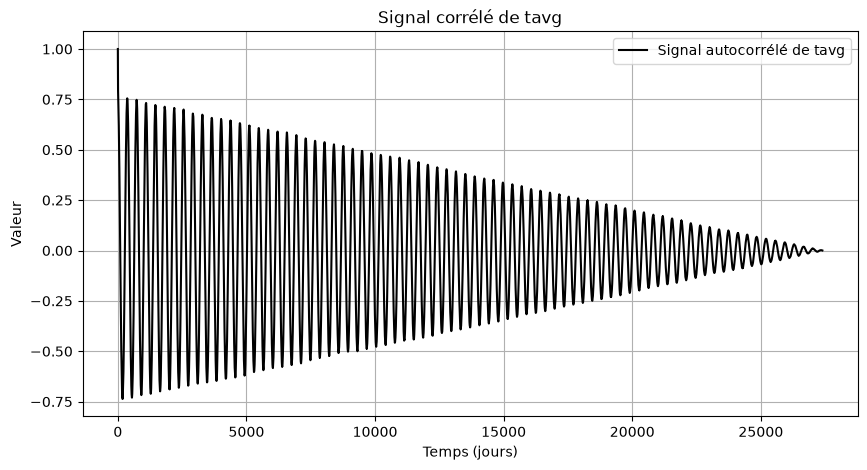

array([5.56448612e+01, 5.30594316e+01, 5.02385765e+01, ...,
       1.26953054e-02, 9.30436164e-03, 5.59646088e-03], shape=(27394,))

In [13]:
test = Signal()

# ampl, freq, unit, phase, mean_value = test.signal_data("prcp", start=0, end=22_000)

# test.reconstruct_signal("tavg", start=0, end=365, n_harmonics=100, plot=True)

test.autocorrelate("tavg",start=0,end=len(test.prcp))
